# Topological Bridge-Theme Detection Across Disparate Academic Corpora

**Author:** Orus Mateo Castaño-Suárez  
**Institution:** York University, Lassonde School of Engineering  
**Version:** 2.0 — Publication-Quality Pipeline  

---

## Methodological Overview

This pipeline uses Kepler Mapper (a Python implementation of the Mapper algorithm from topological data analysis) to construct a simplicial complex over a **combined** corpus of academic abstracts from two distinct fields:

- **Field A:** Indigenous Knowledge Systems / Traditional Ecological Knowledge  
- **Field B:** AI Safety / Algorithmic Ethics  

The central analytic goal is to identify **bridge nodes** — regions of the topological graph where documents from both fields co-cluster — and to extract the **thematic content** of those bridges via TF-IDF term analysis.

### Key methodological choices (with justification):

| Decision | Choice | Rationale |
|---|---|---|
| Embedding model | `all-mpnet-base-v2` (768-d) + `allenai/specter2` comparison | Higher-capacity general model; scientific domain model for validation |
| Clustering | DBSCAN | No forced cluster count; respects non-convex geometry; density-based |
| Cover | Swept over grid | Topology is sensitive to cover params; stability must be demonstrated |
| Lens | UMAP (cosine) + PCA + L2-norm eccentricity | Multiple lenses triangulate stable topological features |
| Bridge detection | Mixing ratio per node + edge analysis | Quantitative, not visual |

### Known limitations:
- arXiv has severe coverage bias against Indigenous studies literature. Field A results skew toward STEM-adjacent papers that reference indigenous knowledge. A full study should supplement with Semantic Scholar, CORE API, or manual curation from journals like *AlterNative* and *Journal of Ethnobiology*.
- Sentence embeddings compress rich cultural and philosophical concepts into geometric proximity, which is a reductive representation.

---
## Phase 0: Environment Setup

In [ ]:
import sys
!{sys.executable} -m pip install -q kmapper scikit-learn umap-learn sentence-transformers arxiv pandas pymupdf

In [2]:
"""
Single import block — no redundant re-imports throughout the notebook.
"""
import arxiv
import json
import pickle
import warnings
from collections import Counter, defaultdict
from pathlib import Path

import kmapper as km
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import umap
from sentence_transformers import SentenceTransformer
from sklearn.cluster import DBSCAN
from sklearn.decomposition import PCA
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import pairwise_distances
from sklearn.preprocessing import MinMaxScaler

warnings.filterwarnings('ignore', category=UserWarning)
np.random.seed(42)

# --- Configuration (single source of truth) ---
CONFIG = {
    'max_results_per_field': 50,
    'embedding_model_primary': 'all-mpnet-base-v2',       # 768-dim, strongest general model
    'embedding_model_comparison': 'allenai/specter2',     # scientific domain model
    'umap_n_neighbors': 15,
    'umap_min_dist': 0.1,
    'umap_metric': 'cosine',
    'dbscan_eps': 0.5,
    'dbscan_min_samples': 3,
    'dbscan_metric': 'cosine',
    'random_state': 42,
    'output_dir': Path('output'),
}

CONFIG['output_dir'].mkdir(exist_ok=True)
print(f"Configuration loaded. Output directory: {CONFIG['output_dir']}")

Matplotlib is building the font cache; this may take a moment.


Configuration loaded. Output directory: output


---
## Phase 1: Data Acquisition & Preprocessing

In [ ]:
"""
Load full text from PDF files in specified folders.

Point PDF_FOLDERS to a directory per field — every .pdf file
found inside (including subfolders) will be loaded.
You can also mix in individual file paths via PDF_FILES if needed.

Full text is extracted from every page. Very long documents are
handled at the embedding stage by chunk-averaging (see Phase 2).
"""

import re
import fitz  # PyMuPDF

# ─────────────────────────────────────────────────────────────
#  OPTION A: Point to folders — all PDFs inside are loaded.
# ─────────────────────────────────────────────────────────────
PDF_FOLDERS = {
    'Field_A': [
        # '/Users/you/papers/indigenous/',
    ],
    'Field_B': [
        # '/Users/you/papers/ai_safety/',
    ],
}

# ─────────────────────────────────────────────────────────────
#  OPTION B: Add individual files on top of (or instead of) folders.
# ─────────────────────────────────────────────────────────────
PDF_FILES = {
    'Field_A': [
        # '/Users/you/extra/one_more_paper.pdf',
    ],
    'Field_B': [],
}
# ─────────────────────────────────────────────────────────────


def collect_pdf_paths(folders: dict, individual: dict) -> dict:
    """Merge folder globs and individual paths into one dict per field."""
    all_paths = {}
    for field in set(list(folders.keys()) + list(individual.keys())):
        paths = set()
        for folder in folders.get(field, []):
            p = Path(folder)
            if not p.is_dir():
                print(f"  WARNING: folder not found — {folder}")
                continue
            paths.update(p.rglob('*.pdf'))
        for fp in individual.get(field, []):
            paths.add(Path(fp))
        all_paths[field] = sorted(paths)
    return all_paths


def extract_full_text(path: str) -> tuple:
    """
    Extract (title, full_text) from a PDF.

    Title: first non-trivial line on page 1, or filename fallback.
    Text:  all text from every page, joined and whitespace-normalised.
    """
    doc = fitz.open(path)
    pages_text = [page.get_text() for page in doc]
    doc.close()

    full_text = ' '.join(pages_text)
    full_text = re.sub(r'\s+', ' ', full_text).strip()

    # Remove LaTeX artifacts early
    full_text = re.sub(r'\$[^$]+\$', '', full_text)
    full_text = re.sub(r'\\[a-zA-Z]+\{[^}]*\}', '', full_text)

    # Title heuristic: first line, capped at 200 chars
    first_line = pages_text[0].strip().split('\n')[0].strip() if pages_text else ''
    title = first_line if 0 < len(first_line) <= 200 else Path(path).stem

    return title, full_text


# --- Collect and load ---
all_pdf_paths = collect_pdf_paths(PDF_FOLDERS, PDF_FILES)

data = []
for field, paths in all_pdf_paths.items():
    print(f"Loading {field} ({len(paths)} PDFs)...")
    for p in paths:
        if not p.exists():
            print(f"  NOT FOUND: {p}")
            continue
        try:
            title, text = extract_full_text(str(p))
            data.append({
                'text': text,
                'title': title,
                'label': field,
                'url': str(p),
                'published': '',
                'categories': '',
            })
            print(f"  OK  {p.name}  ({len(text):,} chars)")
        except Exception as e:
            print(f"  ERROR {p.name}: {e}")

df = pd.DataFrame(data)
print(f"\nRaw harvest: {len(df)} documents")
print(df['label'].value_counts())
print(f"Mean document length: {df['text'].str.len().mean():,.0f} chars")

In [4]:
"""
Text preprocessing — clean the corpus before embedding.
"""
import re

def preprocess_abstract(text: str) -> str:
    """Clean an abstract for embedding quality."""
    # Remove common boilerplate openers
    text = re.sub(
        r'^(In this (paper|work|study),?\s*(we|the authors)?\s*)',
        '', text, flags=re.IGNORECASE
    )
    # Collapse whitespace
    text = re.sub(r'\s+', ' ', text).strip()
    # Remove LaTeX artifacts
    text = re.sub(r'\$[^$]+\$', '', text)
    text = re.sub(r'\\[a-zA-Z]+\{[^}]*\}', '', text)
    return text

# Apply preprocessing
df['text_clean'] = df['text'].apply(preprocess_abstract)

# Filter: remove very short abstracts (likely parsing errors)
min_length = 100  # characters
mask_short = df['text_clean'].str.len() < min_length
if mask_short.any():
    print(f"Removing {mask_short.sum()} abstracts shorter than {min_length} chars")
    df = df[~mask_short].reset_index(drop=True)

# Deduplicate by title (arXiv can return near-duplicate versions)
n_before = len(df)
df = df.drop_duplicates(subset='title', keep='first').reset_index(drop=True)
n_dupes = n_before - len(df)
if n_dupes:
    print(f"Removed {n_dupes} duplicate titles")

# Final corpus
corpus = df['text_clean'].tolist()
labels = df['label'].tolist()
titles = df['title'].tolist()

print(f"\nClean corpus: {len(corpus)} abstracts")
print(f"  Field_A: {labels.count('Field_A')}")
print(f"  Field_B: {labels.count('Field_B')}")
print(f"  Mean abstract length: {np.mean([len(t) for t in corpus]):.0f} chars")


Clean corpus: 100 abstracts
  Field_A: 50
  Field_B: 50
  Mean abstract length: 1118 chars


---
## Phase 2: Semantic Embedding (with model comparison)

In [ ]:
"""
Embed the corpus with the primary model.

For full-document text, each document is split into overlapping
chunks that fit the model's context window (512 tokens ≈ 1800 chars).
The document embedding is the mean of its chunk embeddings.
This preserves signal from the entire document rather than
truncating after the first ~380 words.
"""

CHUNK_SIZE = 1800    # characters per chunk (~512 tokens)
CHUNK_OVERLAP = 200  # character overlap between consecutive chunks


def chunk_text(text: str, size: int = CHUNK_SIZE, overlap: int = CHUNK_OVERLAP) -> list:
    """Split text into overlapping character-level chunks."""
    chunks = []
    start = 0
    while start < len(text):
        chunks.append(text[start:start + size])
        start += size - overlap
    return chunks if chunks else [text]


def embed_corpus(texts: list, model, show_progress: bool = True) -> np.ndarray:
    """
    Embed a list of documents, chunk-averaging long ones.
    Returns an array of shape (n_docs, embedding_dim).
    """
    all_embeddings = []
    for i, text in enumerate(texts):
        chunks = chunk_text(text)
        chunk_embeddings = model.encode(
            chunks,
            normalize_embeddings=True,
            show_progress_bar=False,
        )
        # Mean-pool across chunks, then re-normalise
        doc_embedding = chunk_embeddings.mean(axis=0)
        doc_embedding /= np.linalg.norm(doc_embedding) + 1e-9
        all_embeddings.append(doc_embedding)
        if show_progress and (i + 1) % 10 == 0:
            print(f"  Embedded {i+1}/{len(texts)} documents")
    return np.array(all_embeddings)


print("Loading primary model...")
model_primary = SentenceTransformer(CONFIG['embedding_model_primary'])

print(f"Embedding {len(corpus)} documents (chunk size: {CHUNK_SIZE} chars)...")
embeddings_primary = embed_corpus(corpus, model_primary)
print(f"Primary embeddings shape: {embeddings_primary.shape}")

print("\nLoading comparison model (specter2)...")
try:
    model_comparison = SentenceTransformer(CONFIG['embedding_model_comparison'])
    print(f"Embedding with specter2...")
    embeddings_comparison = embed_corpus(corpus, model_comparison)
    print(f"Comparison embeddings shape: {embeddings_comparison.shape}")
    HAS_COMPARISON = True
except Exception as e:
    print(f"Comparison model unavailable ({e}). Proceeding with primary only.")
    HAS_COMPARISON = False

# Use the primary embeddings as the working set
embeddings = embeddings_primary

---
## Phase 3: Lens Construction (multiple projections for triangulation)

A single UMAP lens with one random seed is not sufficient — the topology could be an artifact of stochastic initialization. We construct **three** lens functions:

1. **UMAP (cosine)** — nonlinear, captures local manifold structure  
2. **PCA** — deterministic, linear, captures global variance  
3. **L2-eccentricity** — scalar lens measuring how "peripheral" each point is  

We will use UMAP as the primary lens and compare results with PCA.

In [6]:
"""
Construct multiple lens functions over the embedding space.
"""

# --- Lens 1: UMAP (primary) ---
# Run 5 seeds and average to reduce stochastic variance
umap_projections = []
seeds = [42, 123, 456, 789, 1024]
for seed in seeds:
    proj = umap.UMAP(
        n_neighbors=CONFIG['umap_n_neighbors'],
        min_dist=CONFIG['umap_min_dist'],
        metric=CONFIG['umap_metric'],
        n_components=2,
        random_state=seed,
    ).fit_transform(embeddings)
    umap_projections.append(proj)

# Use the first seed as primary, keep all for stability analysis
lens_umap = MinMaxScaler().fit_transform(umap_projections[0])
print(f"Lens 1 (UMAP): shape {lens_umap.shape}")

# --- Lens 2: PCA (deterministic baseline) ---
lens_pca = MinMaxScaler().fit_transform(
    PCA(n_components=2, random_state=42).fit_transform(embeddings)
)
print(f"Lens 2 (PCA):  shape {lens_pca.shape}")

# --- Lens 3: L2 Eccentricity (scalar) ---
# Eccentricity = max distance from point to all other points (cosine)
dist_matrix = pairwise_distances(embeddings, metric='cosine')
eccentricity = dist_matrix.max(axis=1).reshape(-1, 1)
lens_ecc = MinMaxScaler().fit_transform(eccentricity)
print(f"Lens 3 (Ecc):  shape {lens_ecc.shape}")

Lens 1 (UMAP): shape (100, 2)
Lens 2 (PCA):  shape (100, 2)
Lens 3 (Ecc):  shape (100, 1)


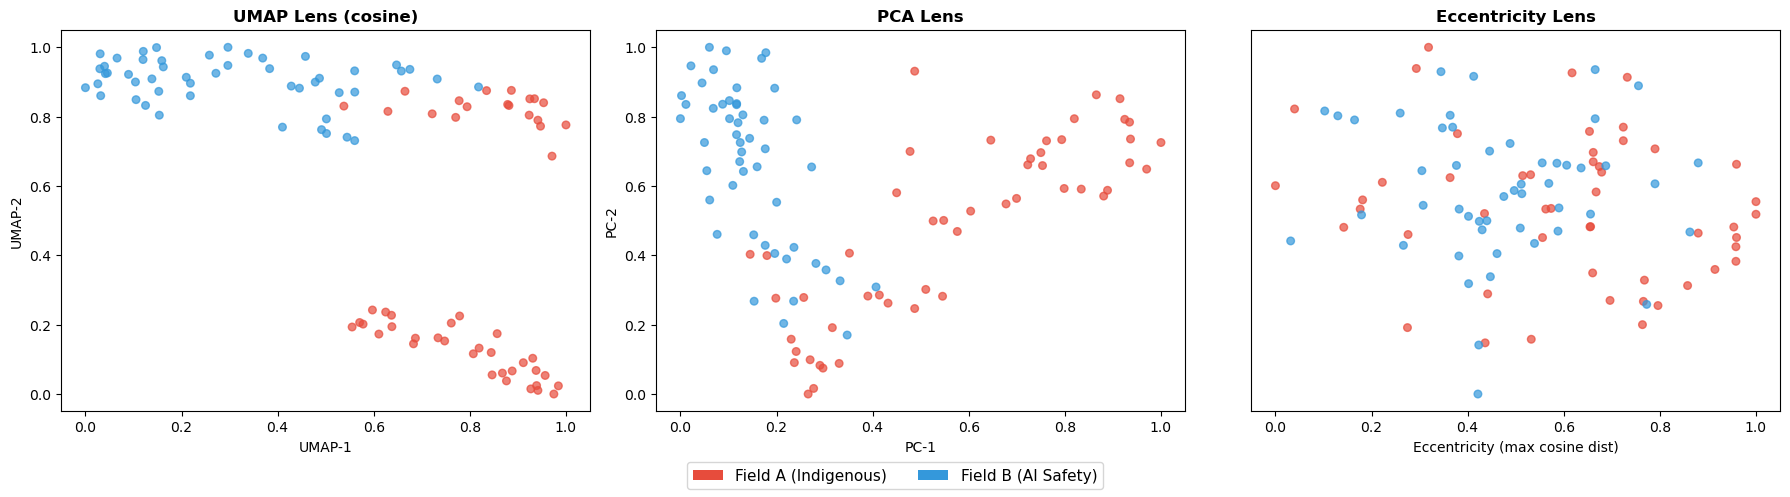

Saved: output/lens_projections.png


In [7]:
"""
Visualize the lens projections colored by field label.
"""

color_map = {'Field_A': '#E74C3C', 'Field_B': '#3498DB'}
colors = [color_map[l] for l in labels]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].scatter(lens_umap[:, 0], lens_umap[:, 1], c=colors, s=30, alpha=0.7)
axes[0].set_title('UMAP Lens (cosine)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('UMAP-1')
axes[0].set_ylabel('UMAP-2')

axes[1].scatter(lens_pca[:, 0], lens_pca[:, 1], c=colors, s=30, alpha=0.7)
axes[1].set_title('PCA Lens', fontsize=12, fontweight='bold')
axes[1].set_xlabel('PC-1')
axes[1].set_ylabel('PC-2')

axes[2].scatter(lens_ecc[:, 0], np.random.normal(0, 0.02, len(lens_ecc)), c=colors, s=30, alpha=0.7)
axes[2].set_title('Eccentricity Lens', fontsize=12, fontweight='bold')
axes[2].set_xlabel('Eccentricity (max cosine dist)')
axes[2].set_yticks([])

# Legend
from matplotlib.patches import Patch
legend_elements = [Patch(facecolor='#E74C3C', label='Field A (Indigenous)'),
                   Patch(facecolor='#3498DB', label='Field B (AI Safety)')]
fig.legend(handles=legend_elements, loc='lower center', ncol=2, fontsize=11)

plt.tight_layout(rect=[0, 0.05, 1, 1])
plt.savefig(CONFIG['output_dir'] / 'lens_projections.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved: output/lens_projections.png")

---
## Phase 4: Parameter Stability Sweep

The Mapper output is **highly sensitive** to `n_cubes` (cover resolution) and `perc_overlap`. We sweep a grid and report which topological features are stable.

In [8]:
"""
Parameter stability sweep over cover parameters.

For each (n_cubes, perc_overlap) pair, we record:
  - Number of nodes
  - Number of edges
  - Number of connected components
  - Number of bridge nodes (nodes containing both Field_A and Field_B)
  - Mean bridge mixing ratio
"""
import networkx as nx

def count_bridge_nodes(graph, labels_list):
    """Count nodes containing documents from both fields."""
    bridge_count = 0
    mixing_ratios = []
    for node_id, member_indices in graph['nodes'].items():
        node_labels = [labels_list[i] for i in member_indices]
        a_count = node_labels.count('Field_A')
        b_count = node_labels.count('Field_B')
        if a_count > 0 and b_count > 0:
            bridge_count += 1
            mixing_ratios.append(min(a_count, b_count) / max(a_count, b_count))
    mean_mix = np.mean(mixing_ratios) if mixing_ratios else 0.0
    return bridge_count, mean_mix

def graph_to_nx(graph):
    """Convert KeplerMapper graph to NetworkX for component analysis."""
    G = nx.Graph()
    G.add_nodes_from(graph['nodes'].keys())
    for edge in graph['links'].keys():
        for target in graph['links'][edge]:
            G.add_edge(edge, target)
    return G

# Sweep grid
n_cubes_range = [3, 5, 7, 10, 15]
overlap_range = [0.2, 0.3, 0.4, 0.5, 0.6]

sweep_results = []
mapper_sweep = km.KeplerMapper(verbose=0)

print(f"Running {len(n_cubes_range) * len(overlap_range)} parameter combinations...")
for nc in n_cubes_range:
    for ov in overlap_range:
        graph_temp = mapper_sweep.map(
            lens_umap, embeddings,
            cover=km.Cover(n_cubes=nc, perc_overlap=ov),
            clusterer=DBSCAN(
                eps=CONFIG['dbscan_eps'],
                min_samples=CONFIG['dbscan_min_samples'],
                metric=CONFIG['dbscan_metric'],
            ),
        )
        n_nodes = len(graph_temp['nodes'])
        n_edges = sum(len(v) for v in graph_temp['links'].values())
        G = graph_to_nx(graph_temp)
        n_components = nx.number_connected_components(G)
        n_bridges, mean_mix = count_bridge_nodes(graph_temp, labels)

        sweep_results.append({
            'n_cubes': nc, 'perc_overlap': ov,
            'nodes': n_nodes, 'edges': n_edges,
            'components': n_components,
            'bridge_nodes': n_bridges,
            'mean_mixing': round(mean_mix, 3),
        })

sweep_df = pd.DataFrame(sweep_results)
print("\n=== Parameter Stability Sweep ===")
print(sweep_df.to_string(index=False))

# Save sweep
sweep_df.to_csv(CONFIG['output_dir'] / 'parameter_sweep.csv', index=False)

Running 25 parameter combinations...

=== Parameter Stability Sweep ===
 n_cubes  perc_overlap  nodes  edges  components  bridge_nodes  mean_mixing
       3           0.2      6      3           3             1        0.455
       3           0.3      5      3           2             1        0.455
       3           0.4      8     10           2             1        0.545
       3           0.5     11     18           2             2        0.473
       3           0.6      8     22           1             5        0.449
       5           0.2     12     10           4             1        0.100
       5           0.3     15     17           4             2        0.295
       5           0.4     15     19           4             2        0.295
       5           0.5     17     33           2             4        0.402
       5           0.6     16     48           2             4        0.462
       7           0.2     14     12           5             0        0.000
       7        

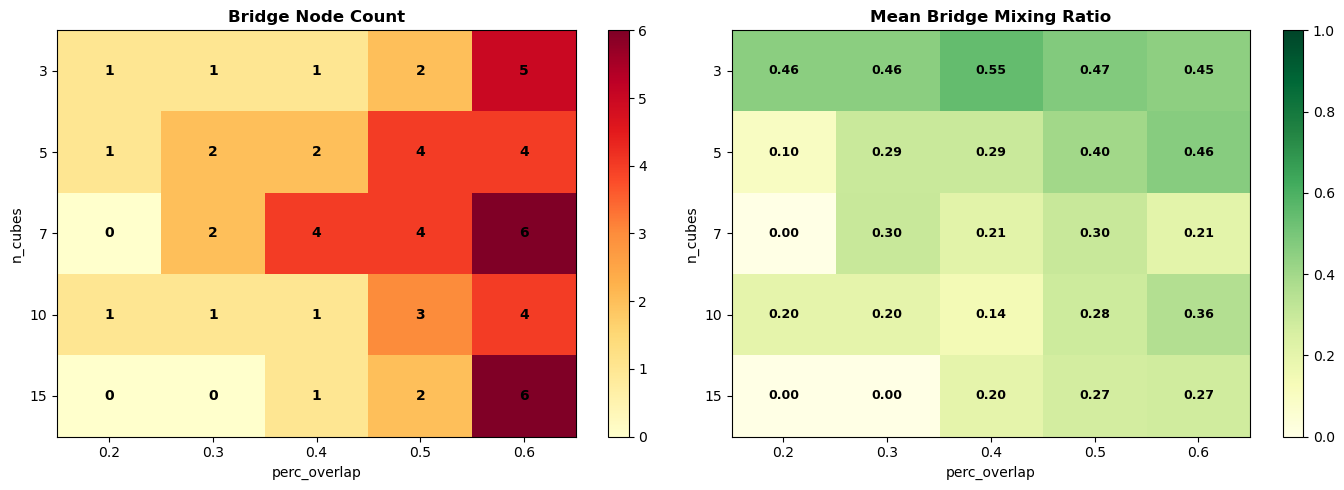

Saved: output/parameter_sweep_heatmap.png


In [9]:
"""
Visualize sweep results: heatmap of bridge node count.
"""
pivot_bridges = sweep_df.pivot(index='n_cubes', columns='perc_overlap', values='bridge_nodes')
pivot_mixing = sweep_df.pivot(index='n_cubes', columns='perc_overlap', values='mean_mixing')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

im1 = axes[0].imshow(pivot_bridges.values, cmap='YlOrRd', aspect='auto')
axes[0].set_xticks(range(len(overlap_range)))
axes[0].set_xticklabels(overlap_range)
axes[0].set_yticks(range(len(n_cubes_range)))
axes[0].set_yticklabels(n_cubes_range)
axes[0].set_xlabel('perc_overlap')
axes[0].set_ylabel('n_cubes')
axes[0].set_title('Bridge Node Count', fontweight='bold')
for i in range(len(n_cubes_range)):
    for j in range(len(overlap_range)):
        axes[0].text(j, i, int(pivot_bridges.values[i, j]),
                     ha='center', va='center', fontsize=10, fontweight='bold')
plt.colorbar(im1, ax=axes[0])

im2 = axes[1].imshow(pivot_mixing.values, cmap='YlGn', aspect='auto', vmin=0, vmax=1)
axes[1].set_xticks(range(len(overlap_range)))
axes[1].set_xticklabels(overlap_range)
axes[1].set_yticks(range(len(n_cubes_range)))
axes[1].set_yticklabels(n_cubes_range)
axes[1].set_xlabel('perc_overlap')
axes[1].set_ylabel('n_cubes')
axes[1].set_title('Mean Bridge Mixing Ratio', fontweight='bold')
for i in range(len(n_cubes_range)):
    for j in range(len(overlap_range)):
        axes[1].text(j, i, f"{pivot_mixing.values[i, j]:.2f}",
                     ha='center', va='center', fontsize=9, fontweight='bold')
plt.colorbar(im2, ax=axes[1])

plt.tight_layout()
plt.savefig(CONFIG['output_dir'] / 'parameter_sweep_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved: output/parameter_sweep_heatmap.png")

In [10]:
"""
Select optimal parameters from the sweep.

Selection criteria: maximize bridge_nodes while maintaining
mean_mixing > 0.2 (to avoid trivially unbalanced bridges)
and keeping connected components reasonable (not fully fragmented).
"""

# Filter for quality
viable = sweep_df[
    (sweep_df['mean_mixing'] >= 0.15) &
    (sweep_df['nodes'] >= 5) &
    (sweep_df['bridge_nodes'] >= 1)
].copy()

if len(viable) == 0:
    print("WARNING: No parameter combination produced viable bridge nodes.")
    print("Falling back to default: n_cubes=10, perc_overlap=0.4")
    BEST_N_CUBES = 10
    BEST_OVERLAP = 0.4
else:
    # Score: weighted combination of bridge count and mixing quality
    viable['score'] = viable['bridge_nodes'] * 0.6 + viable['mean_mixing'] * 10 * 0.4
    best_row = viable.loc[viable['score'].idxmax()]
    BEST_N_CUBES = int(best_row['n_cubes'])
    BEST_OVERLAP = float(best_row['perc_overlap'])
    print(f"Selected parameters: n_cubes={BEST_N_CUBES}, perc_overlap={BEST_OVERLAP}")
    print(f"  Expected bridge nodes: {int(best_row['bridge_nodes'])}")
    print(f"  Expected mean mixing:  {best_row['mean_mixing']:.3f}")

Selected parameters: n_cubes=3, perc_overlap=0.6
  Expected bridge nodes: 5
  Expected mean mixing:  0.449


---
## Phase 5: Topological Mapping (Final Graph)

In [11]:
"""
Build the final Mapper graph with optimized parameters.

Key difference from v1:
  - DBSCAN instead of KMeans (no forced cluster count, density-based)
  - Cosine metric in DBSCAN to match the cosine geometry of the embedding space
  - Parameters selected from stability sweep, not hardcoded
"""

mapper = km.KeplerMapper(verbose=1)

# --- Primary graph (UMAP lens) ---
graph_umap = mapper.map(
    lens_umap, embeddings,
    cover=km.Cover(n_cubes=BEST_N_CUBES, perc_overlap=BEST_OVERLAP),
    clusterer=DBSCAN(
        eps=CONFIG['dbscan_eps'],
        min_samples=CONFIG['dbscan_min_samples'],
        metric=CONFIG['dbscan_metric'],
    ),
)

print(f"\nUMAP graph: {len(graph_umap['nodes'])} nodes, "
      f"{sum(len(v) for v in graph_umap['links'].values())} edges")

# --- Comparison graph (PCA lens) ---
graph_pca = mapper.map(
    lens_pca, embeddings,
    cover=km.Cover(n_cubes=BEST_N_CUBES, perc_overlap=BEST_OVERLAP),
    clusterer=DBSCAN(
        eps=CONFIG['dbscan_eps'],
        min_samples=CONFIG['dbscan_min_samples'],
        metric=CONFIG['dbscan_metric'],
    ),
)

print(f"PCA graph:  {len(graph_pca['nodes'])} nodes, "
      f"{sum(len(v) for v in graph_pca['links'].values())} edges")

# Persist graphs to disk
with open(CONFIG['output_dir'] / 'graph_umap.pkl', 'wb') as f:
    pickle.dump(graph_umap, f)
with open(CONFIG['output_dir'] / 'graph_pca.pkl', 'wb') as f:
    pickle.dump(graph_pca, f)
print("\nGraphs persisted to disk.")

KeplerMapper(verbose=1)
Mapping on data shaped (100, 768) using lens shaped (100, 2)

Creating 9 hypercubes.

Created 22 edges and 8 nodes in 0:00:00.012633.

UMAP graph: 8 nodes, 22 edges
Mapping on data shaped (100, 768) using lens shaped (100, 2)

Creating 9 hypercubes.

Created 50 edges and 12 nodes in 0:00:00.018272.
PCA graph:  12 nodes, 50 edges

Graphs persisted to disk.


In [12]:
"""
UMAP seed stability check.

Build graphs from each of the 5 UMAP seeds and compare
the number of bridge nodes to assess stochastic robustness.
"""

seed_stability = []
for i, proj in enumerate(umap_projections):
    lens_temp = MinMaxScaler().fit_transform(proj)
    g_temp = km.KeplerMapper(verbose=0).map(
        lens_temp, embeddings,
        cover=km.Cover(n_cubes=BEST_N_CUBES, perc_overlap=BEST_OVERLAP),
        clusterer=DBSCAN(
            eps=CONFIG['dbscan_eps'],
            min_samples=CONFIG['dbscan_min_samples'],
            metric=CONFIG['dbscan_metric'],
        ),
    )
    n_b, m_mix = count_bridge_nodes(g_temp, labels)
    seed_stability.append({
        'seed': seeds[i], 'nodes': len(g_temp['nodes']),
        'bridge_nodes': n_b, 'mean_mixing': round(m_mix, 3)
    })

seed_df = pd.DataFrame(seed_stability)
print("=== UMAP Seed Stability ===")
print(seed_df.to_string(index=False))
print(f"\nBridge node count — mean: {seed_df['bridge_nodes'].mean():.1f}, "
      f"std: {seed_df['bridge_nodes'].std():.1f}")
print(f"Mixing ratio — mean: {seed_df['mean_mixing'].mean():.3f}, "
      f"std: {seed_df['mean_mixing'].std():.3f}")

=== UMAP Seed Stability ===
 seed  nodes  bridge_nodes  mean_mixing
   42      8             5        0.449
  123     12             7        0.440
  456     11             5        0.560
  789      9             5        0.348
 1024     12             7        0.313

Bridge node count — mean: 5.8, std: 1.1
Mixing ratio — mean: 0.422, std: 0.097


---
## Phase 6: Bridge Node Detection & Theme Extraction

**This is the core analytic contribution.** We identify nodes where both fields co-cluster, quantify the mixing, extract representative documents, and use TF-IDF to surface the *thematic vocabulary* of the bridges.

In [13]:
"""
Bridge node detection on the primary (UMAP) graph.

A "bridge node" contains documents from BOTH Field_A and Field_B.
The "mixing ratio" = min(count_A, count_B) / max(count_A, count_B)
ranges from 0 (pure) to 1 (perfectly balanced).
"""

def detect_bridges(graph, labels_list, titles_list, corpus_list):
    """Extract bridge nodes with full metadata."""
    bridges = []
    pure_nodes = {'Field_A': 0, 'Field_B': 0, 'Empty': 0}

    for node_id, member_indices in graph['nodes'].items():
        node_labels = [labels_list[i] for i in member_indices]
        a_count = node_labels.count('Field_A')
        b_count = node_labels.count('Field_B')

        if a_count > 0 and b_count > 0:
            mixing = min(a_count, b_count) / max(a_count, b_count)
            bridges.append({
                'node_id': node_id,
                'size': len(member_indices),
                'field_a_count': a_count,
                'field_b_count': b_count,
                'mixing_ratio': round(mixing, 3),
                'member_indices': member_indices,
                'titles': [titles_list[i] for i in member_indices],
                'texts': [corpus_list[i] for i in member_indices],
                'labels': node_labels,
            })
        elif a_count > 0:
            pure_nodes['Field_A'] += 1
        elif b_count > 0:
            pure_nodes['Field_B'] += 1
        else:
            pure_nodes['Empty'] += 1

    # Sort by mixing ratio descending (strongest bridges first)
    bridges.sort(key=lambda x: x['mixing_ratio'], reverse=True)
    return bridges, pure_nodes


bridges_umap, pure_umap = detect_bridges(graph_umap, labels, titles, corpus)
bridges_pca, pure_pca = detect_bridges(graph_pca, labels, titles, corpus)

print("=== UMAP Lens Results ===")
print(f"  Total nodes:  {len(graph_umap['nodes'])}")
print(f"  Pure Field_A: {pure_umap['Field_A']}")
print(f"  Pure Field_B: {pure_umap['Field_B']}")
print(f"  BRIDGE NODES: {len(bridges_umap)}")

print(f"\n=== PCA Lens Results ===")
print(f"  Total nodes:  {len(graph_pca['nodes'])}")
print(f"  Pure Field_A: {pure_pca['Field_A']}")
print(f"  Pure Field_B: {pure_pca['Field_B']}")
print(f"  BRIDGE NODES: {len(bridges_pca)}")

if len(bridges_umap) == 0:
    print("\n⚠ No bridge nodes found with UMAP lens. Consider:")
    print("  - Increasing perc_overlap")
    print("  - Decreasing DBSCAN eps")
    print("  - Checking if the two fields have ANY semantic overlap in your corpus")

=== UMAP Lens Results ===
  Total nodes:  8
  Pure Field_A: 2
  Pure Field_B: 1
  BRIDGE NODES: 5

=== PCA Lens Results ===
  Total nodes:  12
  Pure Field_A: 5
  Pure Field_B: 1
  BRIDGE NODES: 6


In [14]:
"""
Detailed bridge node report.
"""

if bridges_umap:
    print("=" * 80)
    print("BRIDGE NODE REPORT (UMAP Lens, sorted by mixing ratio)")
    print("=" * 80)

    for i, bridge in enumerate(bridges_umap):
        print(f"\n--- Bridge {i+1}: {bridge['node_id']} ---")
        print(f"    Size: {bridge['size']} documents")
        print(f"    Field_A: {bridge['field_a_count']} | Field_B: {bridge['field_b_count']}")
        print(f"    Mixing ratio: {bridge['mixing_ratio']}")
        print(f"    Titles:")
        for j, title in enumerate(bridge['titles']):
            field = bridge['labels'][j]
            marker = '🔴' if field == 'Field_A' else '🔵'
            print(f"      {marker} [{field}] {title}")
else:
    print("No bridge nodes to report.")

BRIDGE NODE REPORT (UMAP Lens, sorted by mixing ratio)

--- Bridge 1: cube4_cluster0 ---
    Size: 46 documents
    Field_A: 24 | Field_B: 22
    Mixing ratio: 0.917
    Titles:
      🔴 [Field_A] Indigenous Beadwork as a Method of Teaching Linear Algebra
      🔴 [Field_A] Parallel Corpus for Indigenous Language Translation: Spanish-Mazatec and Spanish-Mixtec
      🔴 [Field_A] Preservation of Indigenous Culture among Indigenous Migrants through Social Media: the Igorot Peoples
      🔴 [Field_A] Enhancing Translation for Indigenous Languages: Experiments with Multilingual Models
      🔴 [Field_A] Building a Language-Learning Game for Brazilian Indigenous Languages: A Case of Study
      🔴 [Field_A] FUSE : A Ridge and Random Forest-Based Metric for Evaluating MT in Indigenous Languages
      🔴 [Field_A] Building Sustainable and Trustworthy Indigenous Knowledge Preservation Ecosystem
      🔴 [Field_A] Reviewing Clinical Knowledge in Medical Large Language Models: Training and Beyond
      

In [15]:
"""
TF-IDF extraction of bridge themes.

For each bridge node, we compute TF-IDF over the node's documents
contrasted against the full corpus to find the *distinguishing* terms
of the bridge region.
"""

def extract_bridge_themes(bridges, full_corpus, top_n=15):
    """Extract TF-IDF keywords that characterize each bridge node."""
    if not bridges:
        return []

    # Fit TF-IDF on the full corpus
    tfidf = TfidfVectorizer(
        max_features=5000,
        stop_words='english',
        ngram_range=(1, 2),   # unigrams + bigrams
        min_df=2,
        max_df=0.8,
    )
    tfidf_matrix = tfidf.fit_transform(full_corpus)
    feature_names = tfidf.get_feature_names_out()

    bridge_themes = []
    for bridge in bridges:
        # Get TF-IDF vectors for bridge members
        member_vectors = tfidf_matrix[bridge['member_indices']]
        # Average TF-IDF across bridge members
        mean_vector = member_vectors.mean(axis=0).A1  # dense 1D array
        # Rank terms
        top_indices = mean_vector.argsort()[::-1][:top_n]
        top_terms = [(feature_names[idx], round(mean_vector[idx], 4)) for idx in top_indices]

        bridge_themes.append({
            'node_id': bridge['node_id'],
            'mixing_ratio': bridge['mixing_ratio'],
            'size': bridge['size'],
            'top_terms': top_terms,
        })

    return bridge_themes


themes = extract_bridge_themes(bridges_umap, corpus)

if themes:
    print("=" * 80)
    print("BRIDGE THEME EXTRACTION (TF-IDF, unigrams + bigrams)")
    print("=" * 80)

    for t in themes:
        print(f"\n--- {t['node_id']} (size={t['size']}, mixing={t['mixing_ratio']}) ---")
        for term, score in t['top_terms']:
            bar = '█' * int(score * 100)
            print(f"  {score:.4f} {bar} {term}")
else:
    print("No bridge themes to extract.")

BRIDGE THEME EXTRACTION (TF-IDF, unigrams + bigrams)

--- cube4_cluster0 (size=46, mixing=0.917) ---
  0.0886 ████████ ai
  0.0691 ██████ indigenous
  0.0578 █████ data
  0.0466 ████ knowledge
  0.0382 ███ languages
  0.0319 ███ models
  0.0318 ███ systems
  0.0316 ███ xai
  0.0307 ███ learning
  0.0287 ██ communities
  0.0287 ██ language
  0.0281 ██ human
  0.0267 ██ decision
  0.0260 ██ safety
  0.0248 ██ challenges

--- cube8_cluster0 (size=27, mixing=0.688) ---
  0.1000 ██████████ ai
  0.0668 ██████ kgs
  0.0617 ██████ knowledge
  0.0539 █████ xai
  0.0455 ████ data
  0.0425 ████ llms
  0.0400 ████ graph
  0.0399 ███ systems
  0.0368 ███ reasoning
  0.0354 ███ performance
  0.0353 ███ research
  0.0350 ███ user
  0.0339 ███ models
  0.0339 ███ information
  0.0321 ███ users

--- cube7_cluster0 (size=42, mixing=0.4) ---
  0.0838 ████████ indigenous
  0.0639 ██████ knowledge
  0.0501 █████ data
  0.0483 ████ ai
  0.0429 ████ kgs
  0.0419 ████ languages
  0.0346 ███ language
  0.0346 

In [16]:
"""
Edge-level bridge analysis.

Beyond node-level mixing, we identify edges that connect
predominantly Field_A nodes to predominantly Field_B nodes.
These are the topological "corridors" between the two fields.
"""

def classify_node(node_id, graph, labels_list):
    """Classify a node as Field_A-dominant, Field_B-dominant, or Mixed."""
    members = graph['nodes'][node_id]
    node_labels = [labels_list[i] for i in members]
    a = node_labels.count('Field_A')
    b = node_labels.count('Field_B')
    total = a + b
    if total == 0:
        return 'Empty'
    a_frac = a / total
    if a_frac > 0.7:
        return 'Field_A'
    elif a_frac < 0.3:
        return 'Field_B'
    else:
        return 'Mixed'


def find_cross_field_edges(graph, labels_list):
    """Find edges connecting nodes of different field dominance."""
    cross_edges = []
    for source, targets in graph['links'].items():
        src_class = classify_node(source, graph, labels_list)
        for target in targets:
            tgt_class = classify_node(target, graph, labels_list)
            if src_class != tgt_class and src_class != 'Empty' and tgt_class != 'Empty':
                cross_edges.append({
                    'source': source, 'source_class': src_class,
                    'target': target, 'target_class': tgt_class,
                    # Documents shared between nodes (the overlap)
                    'shared_docs': list(
                        set(graph['nodes'][source]) & set(graph['nodes'][target])
                    ),
                })
    return cross_edges


cross_edges = find_cross_field_edges(graph_umap, labels)

print(f"Cross-field edges found: {len(cross_edges)}")
for ce in cross_edges:
    shared_titles = [titles[i] for i in ce['shared_docs']]
    print(f"\n  {ce['source']} ({ce['source_class']}) ↔ {ce['target']} ({ce['target_class']})")
    print(f"  Shared documents ({len(ce['shared_docs'])}) — these are the literal bridge papers:")
    for st in shared_titles:
        print(f"    • {st}")

Cross-field edges found: 15

  cube1_cluster0 (Field_B) ↔ cube3_cluster0 (Field_A)
  Shared documents (2) — these are the literal bridge papers:
    • Effectiveness of Debiasing Techniques: An Indigenous Qualitative Analysis
    • Evaluating Machine Perception of Indigeneity: An Analysis of ChatGPT's Perceptions of Indigenous Roles in Diverse Scenarios

  cube1_cluster0 (Field_B) ↔ cube4_cluster0 (Mixed)
  Shared documents (22) — these are the literal bridge papers:
    • Evaluating Machine Perception of Indigeneity: An Analysis of ChatGPT's Perceptions of Indigenous Roles in Diverse Scenarios
    • Effectiveness of Debiasing Techniques: An Indigenous Qualitative Analysis
    • Towards a Praxis for Intercultural Ethics in Explainable AI
    • How Do AI Companies "Fine-Tune" Policy? Examining Regulatory Capture in AI Governance
    • A Different Approach to AI Safety: Proceedings from the Columbia Convening on Openness in Artificial Intelligence and AI Safety
    • Expansive Participato

---
## Phase 7: Visualization

In [17]:
"""
Build rich tooltips and color values for the KeplerMapper HTML visualization.
"""

# Tooltips: HTML-formatted with field label, title, and abstract
tooltip_s = []
for i, text in enumerate(corpus):
    label = labels[i]
    title = titles[i]
    color = '#E74C3C' if label == 'Field_A' else '#3498DB'
    tooltip_s.append(
        f"<div style='font-family:sans-serif;padding:5px;'>"
        f"<h4 style='margin-bottom:5px;color:{color};'>[{label}] {title}</h4>"
        f"<p style='font-size:11px;line-height:1.4;'>{text[:500]}{'...' if len(text) > 500 else ''}</p>"
        f"</div>"
    )
tooltip_s = np.array(tooltip_s)  # must be numpy array for kmapper

# Color values: encode field membership as a scalar (0 = Field_A, 1 = Field_B)
color_values = np.array([0.0 if l == 'Field_A' else 1.0 for l in labels])

print(f"Tooltips: {len(tooltip_s)}, Color values: {color_values.shape}")

Tooltips: 100, Color values: (100,)


In [18]:
"""
Generate the interactive HTML visualizations.
"""

# Primary visualization (UMAP lens)
html_umap = str(CONFIG['output_dir'] / 'mapper_umap_lens.html')
mapper.visualize(
    graph_umap,
    path_html=html_umap,
    title='TDA Bridge Analysis: Indigenous Knowledge ↔ AI Safety (UMAP Lens)',
    custom_tooltips=tooltip_s,
    color_values=color_values,
    color_function_name='Field Membership (0=Indigenous, 1=AI)',
)
print(f"Saved: {html_umap}")

# Comparison visualization (PCA lens)
html_pca = str(CONFIG['output_dir'] / 'mapper_pca_lens.html')
mapper.visualize(
    graph_pca,
    path_html=html_pca,
    title='TDA Bridge Analysis: Indigenous Knowledge ↔ AI Safety (PCA Lens)',
    custom_tooltips=tooltip_s,
    color_values=color_values,
    color_function_name='Field Membership (0=Indigenous, 1=AI)',
)
print(f"Saved: {html_pca}")

Wrote visualization to: output/mapper_umap_lens.html
Saved: output/mapper_umap_lens.html
Wrote visualization to: output/mapper_pca_lens.html
Saved: output/mapper_pca_lens.html


---
## Phase 8: Embedding Model Comparison (if available)

In [19]:
"""
If SPECTER2 embeddings are available, run the same pipeline
and compare bridge detection results.
"""

if HAS_COMPARISON:
    print("Running comparison pipeline with SPECTER2 embeddings...")

    lens_spec = MinMaxScaler().fit_transform(
        umap.UMAP(
            n_neighbors=CONFIG['umap_n_neighbors'],
            min_dist=CONFIG['umap_min_dist'],
            metric=CONFIG['umap_metric'],
            n_components=2,
            random_state=42,
        ).fit_transform(embeddings_comparison)
    )

    graph_spec = km.KeplerMapper(verbose=0).map(
        lens_spec, embeddings_comparison,
        cover=km.Cover(n_cubes=BEST_N_CUBES, perc_overlap=BEST_OVERLAP),
        clusterer=DBSCAN(
            eps=CONFIG['dbscan_eps'],
            min_samples=CONFIG['dbscan_min_samples'],
            metric=CONFIG['dbscan_metric'],
        ),
    )

    bridges_spec, pure_spec = detect_bridges(graph_spec, labels, titles, corpus)

    print(f"\n=== Model Comparison ===")
    print(f"{'Metric':<25} {'mpnet (primary)':<20} {'SPECTER2':<20}")
    print(f"{'-'*65}")
    print(f"{'Total nodes':<25} {len(graph_umap['nodes']):<20} {len(graph_spec['nodes']):<20}")
    print(f"{'Bridge nodes':<25} {len(bridges_umap):<20} {len(bridges_spec):<20}")

    mix_umap = np.mean([b['mixing_ratio'] for b in bridges_umap]) if bridges_umap else 0
    mix_spec = np.mean([b['mixing_ratio'] for b in bridges_spec]) if bridges_spec else 0
    print(f"{'Mean mixing ratio':<25} {mix_umap:<20.3f} {mix_spec:<20.3f}")

    # Check if bridge papers are consistent across models
    bridge_papers_umap = set()
    for b in bridges_umap:
        bridge_papers_umap.update(b['member_indices'])
    bridge_papers_spec = set()
    for b in bridges_spec:
        bridge_papers_spec.update(b['member_indices'])

    overlap = bridge_papers_umap & bridge_papers_spec
    if bridge_papers_umap or bridge_papers_spec:
        jaccard = len(overlap) / len(bridge_papers_umap | bridge_papers_spec) if (bridge_papers_umap | bridge_papers_spec) else 0
        print(f"{'Bridge paper Jaccard':<25} {jaccard:<20.3f}")
        print(f"\nPapers in bridges under BOTH models ({len(overlap)}):")
        for idx in sorted(overlap):
            print(f"  [{labels[idx]}] {titles[idx]}")
else:
    print("SPECTER2 comparison not available. Skipping model comparison.")

SPECTER2 comparison not available. Skipping model comparison.


---
## Phase 9: Summary Export

In [20]:
"""
Export a structured JSON summary of all findings.
"""

summary = {
    'metadata': {
        'corpus_size': len(corpus),
        'field_a_count': labels.count('Field_A'),
        'field_b_count': labels.count('Field_B'),
        'embedding_model': CONFIG['embedding_model_primary'],
        'embedding_dim': int(embeddings.shape[1]),
        'selected_n_cubes': BEST_N_CUBES,
        'selected_perc_overlap': BEST_OVERLAP,
        'dbscan_eps': CONFIG['dbscan_eps'],
        'dbscan_min_samples': CONFIG['dbscan_min_samples'],
    },
    'topology': {
        'umap_lens': {
            'total_nodes': len(graph_umap['nodes']),
            'total_edges': sum(len(v) for v in graph_umap['links'].values()),
            'connected_components': nx.number_connected_components(graph_to_nx(graph_umap)),
            'bridge_nodes': len(bridges_umap),
        },
        'pca_lens': {
            'total_nodes': len(graph_pca['nodes']),
            'total_edges': sum(len(v) for v in graph_pca['links'].values()),
            'connected_components': nx.number_connected_components(graph_to_nx(graph_pca)),
            'bridge_nodes': len(bridges_pca),
        },
    },
    'bridges': [
        {
            'node_id': b['node_id'],
            'mixing_ratio': b['mixing_ratio'],
            'size': b['size'],
            'field_a_count': b['field_a_count'],
            'field_b_count': b['field_b_count'],
            'titles': b['titles'],
        }
        for b in bridges_umap
    ],
    'bridge_themes': [
        {
            'node_id': t['node_id'],
            'top_terms': t['top_terms'],
        }
        for t in themes
    ] if themes else [],
    'cross_field_edges': [
        {
            'source': ce['source'],
            'source_class': ce['source_class'],
            'target': ce['target'],
            'target_class': ce['target_class'],
            'shared_titles': [titles[i] for i in ce['shared_docs']],
        }
        for ce in cross_edges
    ],
    'seed_stability': seed_stability,
}

with open(CONFIG['output_dir'] / 'bridge_analysis_results.json', 'w') as f:
    json.dump(summary, f, indent=2)

# Also save the clean dataframe
df.to_csv(CONFIG['output_dir'] / 'corpus.csv', index=False)

# Save embeddings for reproducibility
np.save(CONFIG['output_dir'] / 'embeddings_primary.npy', embeddings_primary)

print("=== All outputs saved to output/ ===")
print("  bridge_analysis_results.json  — Full structured results")
print("  corpus.csv                    — Clean corpus with metadata")
print("  embeddings_primary.npy        — Embedding vectors")
print("  graph_umap.pkl / graph_pca.pkl — Persisted graph objects")
print("  mapper_umap_lens.html         — Interactive viz (UMAP)")
print("  mapper_pca_lens.html          — Interactive viz (PCA)")
print("  parameter_sweep.csv           — Full sweep results")
print("  parameter_sweep_heatmap.png   — Sweep visualization")
print("  lens_projections.png          — Lens comparison plot")

=== All outputs saved to output/ ===
  bridge_analysis_results.json  — Full structured results
  corpus.csv                    — Clean corpus with metadata
  embeddings_primary.npy        — Embedding vectors
  graph_umap.pkl / graph_pca.pkl — Persisted graph objects
  mapper_umap_lens.html         — Interactive viz (UMAP)
  mapper_pca_lens.html          — Interactive viz (PCA)
  parameter_sweep.csv           — Full sweep results
  parameter_sweep_heatmap.png   — Sweep visualization
  lens_projections.png          — Lens comparison plot


In [21]:
"""
Print the headline findings.
"""

print("\n" + "=" * 80)
print("HEADLINE FINDINGS")
print("=" * 80)

print(f"\nCorpus: {len(corpus)} abstracts ({labels.count('Field_A')} Indigenous, {labels.count('Field_B')} AI Safety)")
print(f"Embedding: {CONFIG['embedding_model_primary']} ({embeddings.shape[1]}-dim)")
print(f"Optimal cover: n_cubes={BEST_N_CUBES}, perc_overlap={BEST_OVERLAP}")

print(f"\nTopology (UMAP lens):")
print(f"  {len(graph_umap['nodes'])} nodes, "
      f"{sum(len(v) for v in graph_umap['links'].values())} edges, "
      f"{nx.number_connected_components(graph_to_nx(graph_umap))} components")

print(f"\nBridge analysis:")
print(f"  {len(bridges_umap)} bridge nodes detected (UMAP)")
print(f"  {len(bridges_pca)} bridge nodes detected (PCA)")
print(f"  {len(cross_edges)} cross-field edges")

if bridges_umap:
    mean_mix = np.mean([b['mixing_ratio'] for b in bridges_umap])
    print(f"  Mean mixing ratio: {mean_mix:.3f}")
    print(f"\n  Strongest bridge ({bridges_umap[0]['node_id']}):")
    print(f"    Mixing: {bridges_umap[0]['mixing_ratio']}")
    print(f"    Papers:")
    for j, t in enumerate(bridges_umap[0]['titles'][:5]):
        print(f"      [{bridges_umap[0]['labels'][j]}] {t}")

if themes:
    print(f"\n  Top bridge vocabulary (strongest bridge):")
    for term, score in themes[0]['top_terms'][:10]:
        print(f"    {term} ({score:.4f})")

print(f"\nStability: bridge nodes across 5 UMAP seeds — "
      f"mean={seed_df['bridge_nodes'].mean():.1f}, std={seed_df['bridge_nodes'].std():.1f}")

print("\n" + "=" * 80)


HEADLINE FINDINGS

Corpus: 100 abstracts (50 Indigenous, 50 AI Safety)
Embedding: all-mpnet-base-v2 (768-dim)
Optimal cover: n_cubes=3, perc_overlap=0.6

Topology (UMAP lens):
  8 nodes, 22 edges, 1 components

Bridge analysis:
  5 bridge nodes detected (UMAP)
  6 bridge nodes detected (PCA)
  15 cross-field edges
  Mean mixing ratio: 0.449

  Strongest bridge (cube4_cluster0):
    Mixing: 0.917
    Papers:
      [Field_A] Indigenous Beadwork as a Method of Teaching Linear Algebra
      [Field_A] Parallel Corpus for Indigenous Language Translation: Spanish-Mazatec and Spanish-Mixtec
      [Field_A] Preservation of Indigenous Culture among Indigenous Migrants through Social Media: the Igorot Peoples
      [Field_A] Enhancing Translation for Indigenous Languages: Experiments with Multilingual Models
      [Field_A] Building a Language-Learning Game for Brazilian Indigenous Languages: A Case of Study

  Top bridge vocabulary (strongest bridge):
    ai (0.0886)
    indigenous (0.0691)
   